In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.value import Params, add_value
from src.strategies import curve, select_targets, bootstrap_selisih, LABEL

sc = pd.read_parquet("../data/scored.parquet")
P = Params()
v = add_value(sc, P)
semua = len(v) * P.eff_cost        # biaya menghubungi semua = Rp 35.215.000

In [2]:
# a) Dua cara menghitung harus sama
for s in ["risiko", "untung"]:
    for b in [10e6, 15e6, 21e6]:
        _, r = select_targets(v, b, P, s)
        c = curve(v, P, [b]).set_index("strategi").loc[s]
        assert np.isclose(r["perkiraan"], c["perkiraan"], rtol=1e-3), (s, b, "perkiraan")
        assert np.isclose(r["kenyataan"], c["kenyataan"], rtol=1e-3), (s, b, "kenyataan")
print("OK: dua cara hitung cocok")

# b) Budget penuh: harus sama dengan Step 13
t = curve(v, P, [semua]).set_index("strategi")
print(t[["n", "biaya", "perkiraan", "kenyataan", "churner"]].round(0))
assert abs(t.loc["untung", "perkiraan"] - 92_367_154) < 1
assert t.loc["risiko", "n"] == 7043 and t.loc["acak", "n"] == 7043
print("OK: cocok dengan Step 13")

OK: dua cara hitung cocok
             n       biaya   perkiraan   kenyataan  churner
strategi                                                   
acak      7043  35215000.0  83332791.0  83373978.0   1869.0
risiko    7043  35215000.0  83332791.0  83373978.0   1869.0
untung    4195  20975000.0  92367154.0  92652884.0   1714.0
OK: cocok dengan Step 13


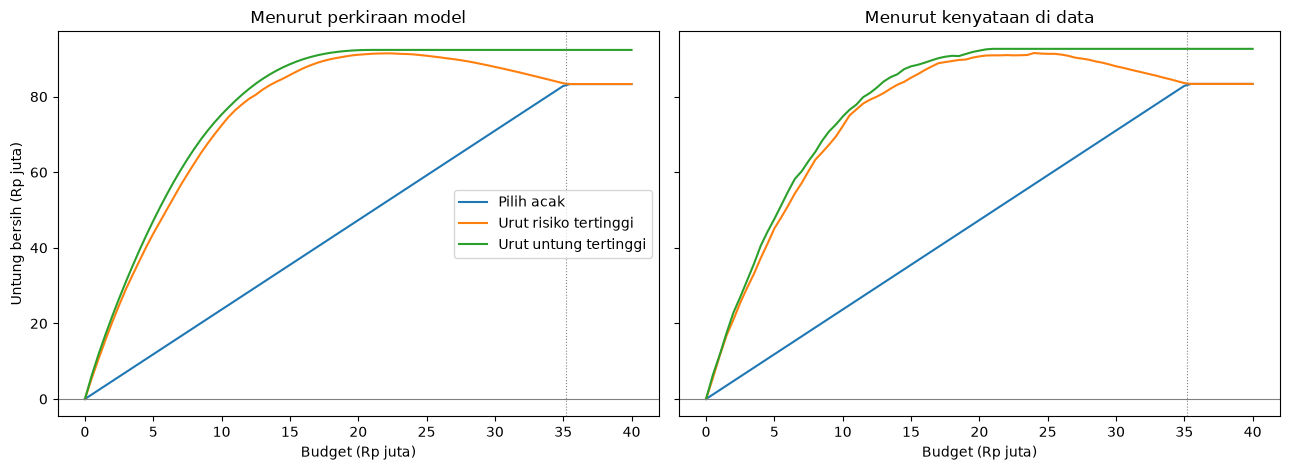

In [3]:
budgets = np.arange(0, 40_000_001, 500_000)
cur = curve(v, P, budgets)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a, kol, judul in [(ax[0], "perkiraan", "Menurut perkiraan model"),
                      (ax[1], "kenyataan", "Menurut kenyataan di data")]:
    for s, g in cur.groupby("strategi"):
        a.plot(g["budget"] / 1e6, g[kol] / 1e6, label=LABEL[s])
    a.axhline(0, color="gray", lw=0.8)
    a.axvline(semua / 1e6, color="gray", ls=":", lw=0.8)   # titik "hubungi semua"
    a.set_title(judul)
    a.set_xlabel("Budget (Rp juta)")
ax[0].set_ylabel("Untung bersih (Rp juta)")
ax[0].legend()
plt.tight_layout()
plt.savefig("../reports/figures/net_value_vs_budget.png", dpi=150)
plt.show()

In [4]:
pilih = [5e6, 10e6, 15e6, 21e6, semua]
t = curve(v, P, pilih)
for kol in ["n", "perkiraan", "kenyataan", "churner"]:
    tab = t.pivot(index="budget", columns="strategi", values=kol)
    tab = (tab / 1e6).round(1) if kol in ("perkiraan", "kenyataan") else tab.round(0)
    print(f"\n{kol}" + (" (Rp juta)" if kol in ("perkiraan", "kenyataan") else ""))
    print(tab)
t.to_csv("../reports/strategy_comparison.csv", index=False)


n
strategi    acak  risiko  untung
budget                          
5000000.0   1000    1000    1000
10000000.0  2000    2000    2000
15000000.0  3000    3000    3000
21000000.0  4200    4200    4195
35215000.0  7043    7043    4195

perkiraan (Rp juta)
strategi    acak  risiko  untung
budget                          
5000000.0   11.8    43.8    47.2
10000000.0  23.7    72.4    75.3
15000000.0  35.5    85.7    88.6
21000000.0  49.7    91.4    92.4
35215000.0  83.3    83.3    92.4

kenyataan (Rp juta)
strategi    acak  risiko  untung
budget                          
5000000.0   11.8    45.1    47.7
10000000.0  23.7    72.2    74.7
15000000.0  35.5    85.0    88.0
21000000.0  49.7    90.9    92.7
35215000.0  83.4    83.4    92.7

churner
strategi      acak  risiko  untung
budget                            
5000000.0    265.0   727.0   697.0
10000000.0   531.0  1213.0  1161.0
15000000.0   796.0  1536.0  1488.0
21000000.0  1115.0  1743.0  1714.0
35215000.0  1869.0  1869.0  1714.0


In [6]:
for b in [10e6, 21e6, semua]:
    r = bootstrap_selisih(v, P, b)
    for nama, (rata, lo, hi) in r.items():
        print(f"Rp {b/1e6:5.1f} juta | {nama:17s}: {rata/1e6:+6.2f} juta   "
              f"rentang 95%: {lo/1e6:+.2f} sampai {hi/1e6:+.2f}")

Rp  10.0 juta | untung vs risiko :  +2.39 juta   rentang 95%: +0.95 sampai +3.86
Rp  10.0 juta | untung vs acak   : +51.01 juta   rentang 95%: +48.53 sampai +53.55
Rp  21.0 juta | untung vs risiko :  +1.68 juta   rentang 95%: +0.75 sampai +2.75
Rp  21.0 juta | untung vs acak   : +42.91 juta   rentang 95%: +41.07 sampai +44.92
Rp  35.2 juta | untung vs risiko :  +9.27 juta   rentang 95%: +8.36 sampai +10.14
Rp  35.2 juta | untung vs acak   :  +9.27 juta   rentang 95%: +8.36 sampai +10.14


In [7]:
tes = v[v["split"] == "test"].reset_index(drop=True)
semua_tes = len(tes) * P.eff_cost
pilih_t = [1e6, 2e6, 3e6, 4.2e6, semua_tes]
print(curve(tes, P, pilih_t)
      .pivot(index="budget", columns="strategi", values="kenyataan")
      .div(1e6).round(2))

strategi    acak  risiko  untung
budget                          
1000000.0   2.31    9.34    9.64
2000000.0   4.62   14.66   14.68
3000000.0   6.92   16.92   17.22
4200000.0   9.69   17.80   18.00
7045000.0  16.26   16.26   18.00
